# k-최근접 이웃 회귀

<table align="left">
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/rickiepark/hg-mldl/blob/master/3-1.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />구글 코랩에서 실행하기</a>
  </td>
</table>

## 데이터 준비

In [34]:
import numpy as np

In [35]:
beak_length = np.array(
    [  8.2, 8.5, 8.7, 9.0, 9.1, 9.3, 9.5, 9.7,
    9.8, 10.0, 8.8, 9.2, 9.6, 10.2, 8.6, 9.4,
    10.1, 8.9, 9.9, 10.3, 8.4, 9.0, 9.7, 10.0,
    8.7, 9.5, 10.4, 9.3, 8.9, 9.8, 10.1, 9.2,
    8.5, 9.6, 10.2,

    12.5, 13.0, 13.4, 13.8, 14.0, 14.3, 14.5, 14.8,
    15.0, 15.3, 12.8, 13.6, 14.2, 15.5]
     )
beak_height = np.array(
    [5.8, 6.1, 5.9, 6.3, 6.0, 6.5, 6.2, 6.7,
    6.4, 6.8, 6.1, 6.4, 6.0, 6.6, 5.7, 6.3,
    6.9, 6.2, 6.5, 6.7, 5.9, 6.1, 6.3, 6.4,
    6.0, 6.6, 6.8, 6.2, 5.8, 6.7, 6.5, 6.0,
    5.6, 6.1, 6.9,

    3.2, 3.0, 3.3, 2.9, 3.1, 2.8, 3.2, 2.7,
    3.0, 2.9, 3.1, 2.8, 3.0, 2.7]
     )

In [36]:
import matplotlib.pyplot as plt

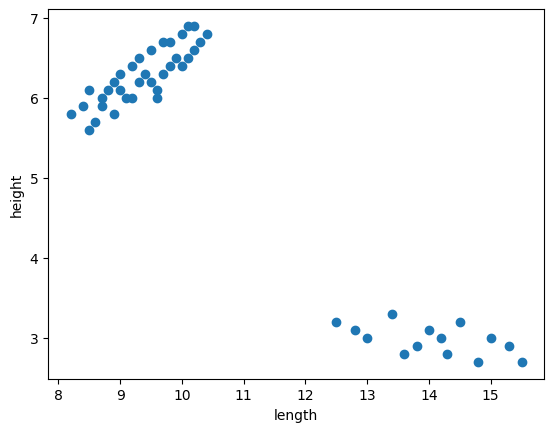

In [37]:
plt.scatter(beak_length, beak_height)
plt.xlabel('length')
plt.ylabel('height')
plt.show()

In [38]:
from sklearn.model_selection import train_test_split

In [39]:
train_input, test_input, train_target, test_target = train_test_split(
    beak_length, beak_height, random_state=42)

In [40]:
print(train_input.shape, test_input.shape)

(36,) (13,)


In [41]:
test_array = np.array([1,2,3,4])
print(test_array.shape)

(4,)


In [42]:
test_array = test_array.reshape(2, 2)
print(test_array.shape)

(2, 2)


In [43]:
# 아래 코드의 주석을 제거하고 실행하면 에러가 발생합니다
# test_array = test_array.reshape(2, 3)

In [44]:
train_input = train_input.reshape(-1, 1)
test_input = test_input.reshape(-1, 1)

In [45]:
print(train_input.shape, test_input.shape)

(36, 1) (13, 1)


## 결정 계수 ($ R^2$)

In [55]:
from sklearn.neighbors import KNeighborsRegressor

In [56]:
knr = KNeighborsRegressor()
# k-최근접 이웃 회귀 모델을 훈련합니다
knr.fit(train_input, train_target)

KNeighborsRegressor()

In [57]:
knr.score(test_input, test_target)

0.981736487233337

In [58]:
from sklearn.metrics import mean_absolute_error

In [59]:
# 테스트 세트에 대한 예측을 만듭니다
test_prediction = knr.predict(test_input)
# 테스트 세트에 대한 평균 절댓값 오차를 계산합니다
mae = mean_absolute_error(test_target, test_prediction)
print(mae)

0.1615384615384616


## 과대적합 vs 과소적합

In [51]:
print(knr.score(train_input, train_target))

0.9878832847510526


In [52]:
# 이웃의 갯수를 3으로 설정합니다
knr.n_neighbors = 3
# 모델을 다시 훈련합니다
knr.fit(train_input, train_target)
print(knr.score(train_input, train_target))

0.98739805082001


In [53]:
print(knr.score(test_input, test_target))

0.9800424941355637


## 확인문제

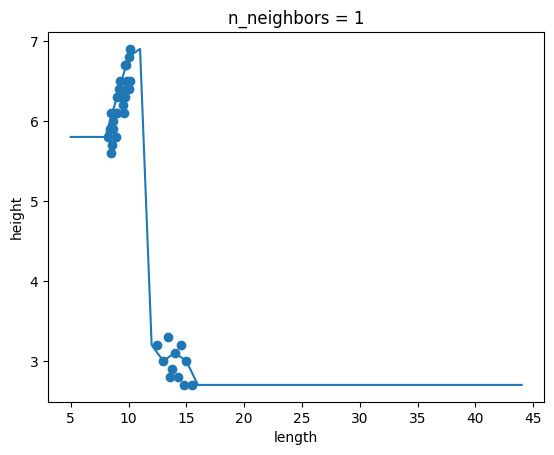

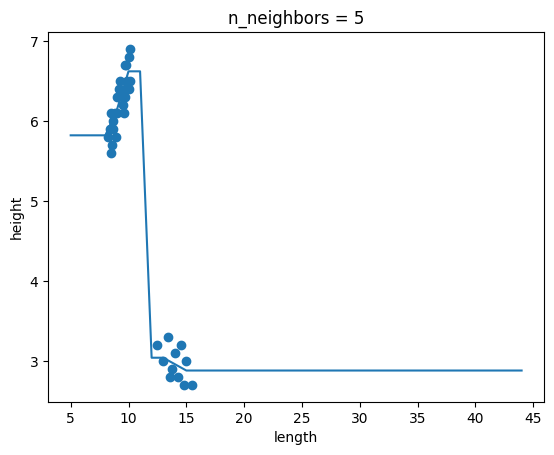

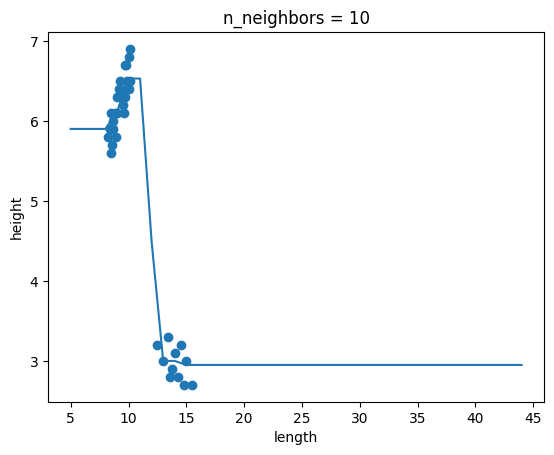

In [54]:
# k-최근접 이웃 회귀 객체를 만듭니다
knr = KNeighborsRegressor()
# 5에서 45까지 x 좌표를 만듭니다
x = np.arange(5, 45).reshape(-1, 1)

# n = 1, 5, 10일 때 예측 결과를 그래프로 그립니다.
for n in [1, 5, 10]:
    # 모델 훈련
    knr.n_neighbors = n
    knr.fit(train_input, train_target)
    # 지정한 범위 x에 대한 예측 구하기
    prediction = knr.predict(x)
    # 훈련 세트와 예측 결과 그래프 그리기
    plt.scatter(train_input, train_target)
    plt.plot(x, prediction)
    plt.title('n_neighbors = {}'.format(n))
    plt.xlabel('length')
    plt.ylabel('height')
    plt.show()